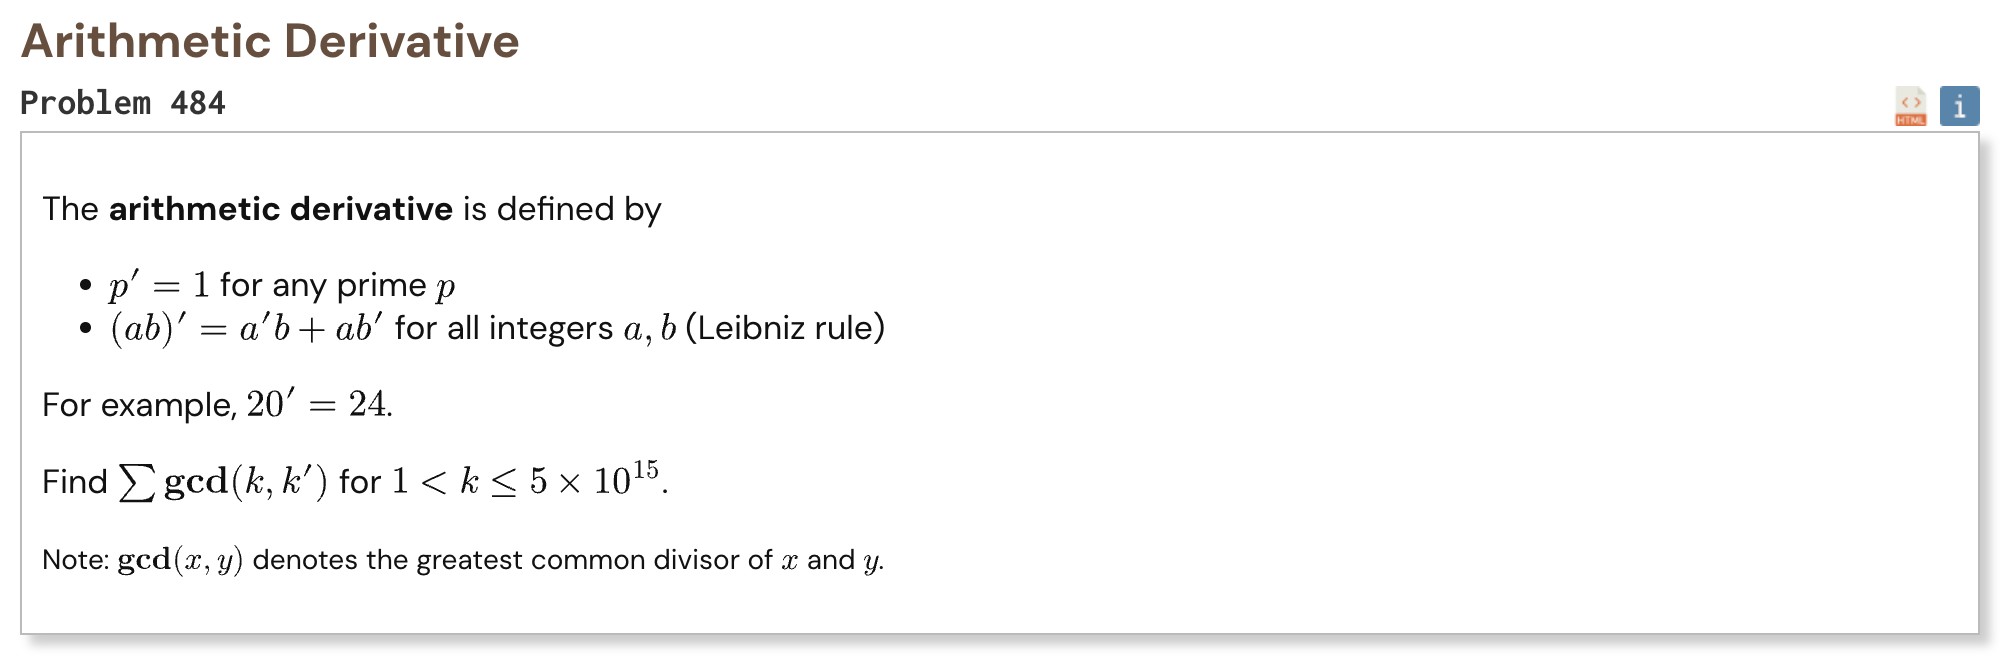

## Initial approach

- express the gcd using the prime powers inside each number
- this gcd function behaves multiplicatively across different primes
- convert the total into a divisor sum so each divisor contributes to many numbers at once
- divisors containing a prime only once give no extra contribution
- this means only powerful numbers need to be generated
- use a depth first search over prime powers instead of checking every number up to the huge limit
- generate the needed primes with a compact sieve and accumulate all contributions

In [1]:
%%time

import math
import sys
from array import array

N = 5 * 10**15

def primes_upto(n):
    size = n // 2 + 1
    sieve = bytearray(b"\x01") * size
    sieve[0] = 0

    limit = math.isqrt(n)

    for p in range(3, limit + 1, 2):
        if sieve[p // 2]:
            start = p * p // 2
            sieve[start::p] = b"\x00" * (
                (size - start - 1) // p + 1
            )

    primes = array("I", [2])

    for i in range(1, size):
        if sieve[i]:
            primes.append(2 * i + 1)

    return primes

primes = primes_upto(math.isqrt(N))
sys.setrecursionlimit(10000)

def dfs(start, limit):
    total = 0

    for i in range(start, len(primes)):
        p = primes[i]
        p2 = p * p
        quotient = limit // p2

        if quotient == 0:
            break

        exponent_mod = 1
        previous_g = 1
        current_g = 1

        while quotient:
            exponent_mod += 1

            if exponent_mod != 1:
                if exponent_mod == p:
                    current_g *= p2
                    exponent_mod = 0
                else:
                    current_g *= p

                contribution = current_g - previous_g

                total += contribution * quotient

                if quotient > p2:
                    total += contribution * dfs(
                        i + 1,
                        quotient
                    )

                previous_g = current_g

            quotient //= p

    return total

result = N - 1 + dfs(0, N)

print("Result:", result)

Result: 8907904768686152599
CPU times: user 17.8 s, sys: 94.9 ms, total: 17.9 s
Wall time: 17.9 s
